## Pregunta 1 — Pirámide Laplaciana y transformada starlet

### Importaciones

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from zipfile import ZipFile
from io import BytesIO
import tifffile
import p1

In [35]:
import importlib
importlib.reload(p1)

<module 'p1' from 'c:\\Users\\apfib\\OneDrive\\Desktop\\IEE2714\\t4-IEE2714\\p1.py'>

### Cargar imagen y extraer luminancia

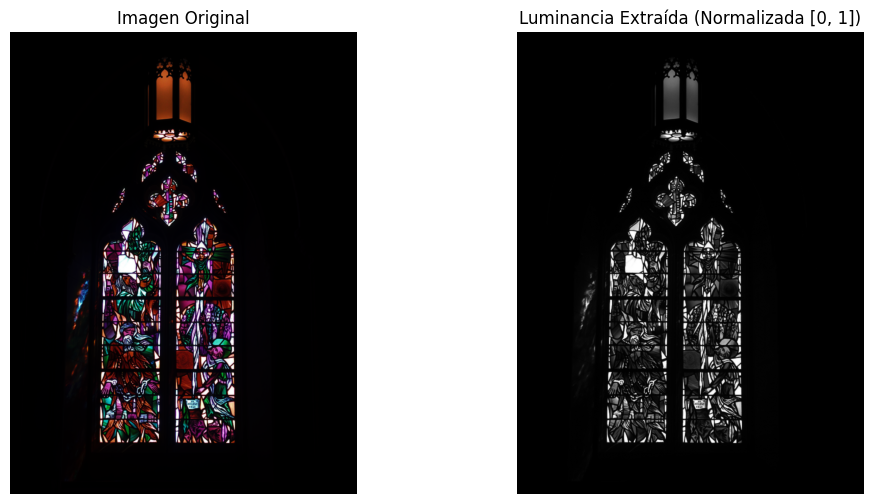

In [36]:
# Carga de imagen desde archivos_t4.zip
with ZipFile('archivos_t4.zip') as zf:
    nombre = next(
        (n for n in zf.namelist() if n.lower().endswith('cathedral.tif')),
        None
    )
    datos = zf.read(nombre)
    raw_img = tifffile.imread(BytesIO(datos))


# Extracción de luminancia
image = p1.extraer_luminancia(raw_img)

# Visualización (normalizando raw_img para evitar clipping en Matplotlib)
raw_img_vis = (raw_img - raw_img.min()) / (raw_img.max() - raw_img.min())

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(raw_img_vis)
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image, cmap='gray')
plt.title('Luminancia Extraída (Normalizada [0, 1])')
plt.axis('off')
plt.show()

### Descomposición y Verificación de Reconstrucción
Verificamos que ambas representaciones recuperen la imagen de entrada sin error significativo (RMSE $\approx 0$).

RMSE Reconstrucción Pirámide Laplaciana: 2.63e-18
RMSE Reconstrucción Transformada Starlet: 1.21e-17


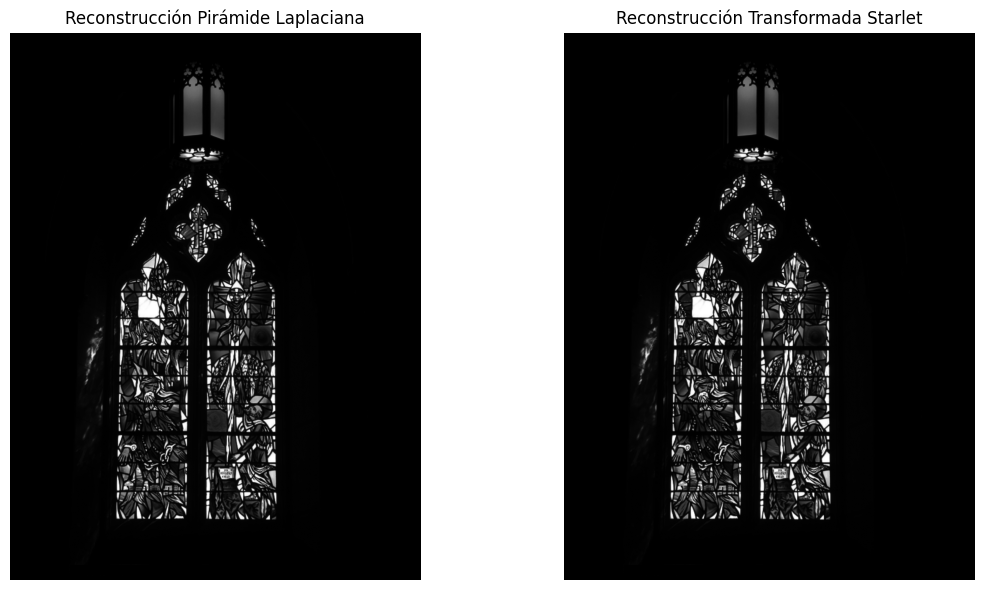

In [37]:
# Descomposición en 5 niveles
lap_detalles, lap_res = p1.piramide_laplaciana(image, niveles=5)
star_detalles, star_res = p1.transformada_starlet(image, niveles=5)

# Verificar reconstrucción exacta
lap_rec = p1.reconstruccion_laplaciana(lap_detalles, lap_res)
star_rec = p1.reconstruct_starlet_transform(star_detalles, star_res)

lap_rmse = p1.calculate_rmse(image, lap_rec)
star_rmse = p1.calculate_rmse(image, star_rec)

print(f'RMSE Reconstrucción Pirámide Laplaciana: {lap_rmse:.2e}')
print(f'RMSE Reconstrucción Transformada Starlet: {star_rmse:.2e}')
# Visualización de reconstrucciones
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(lap_rec, cmap='gray')
plt.title('Reconstrucción Pirámide Laplaciana')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(star_rec, cmap='gray')
plt.title('Reconstrucción Transformada Starlet')
plt.axis('off')

plt.tight_layout()
plt.show()

**Análisis del residual:**
Dado que no se aplicó ningún filtro ni modificación a las capas, las representaciones logran recuperar la imagen de entrada. La ínfima diferencia numérica residual se debe a los errores de redondeo acumulados durante las convoluciones e interpolaciones.

## Experimentación y Análisis

### 1. Visualización de Capas Multiescala
Visualizamos las 5 capas de detalle y el residual de la Pirámide Laplaciana y la Transformada Starlet.

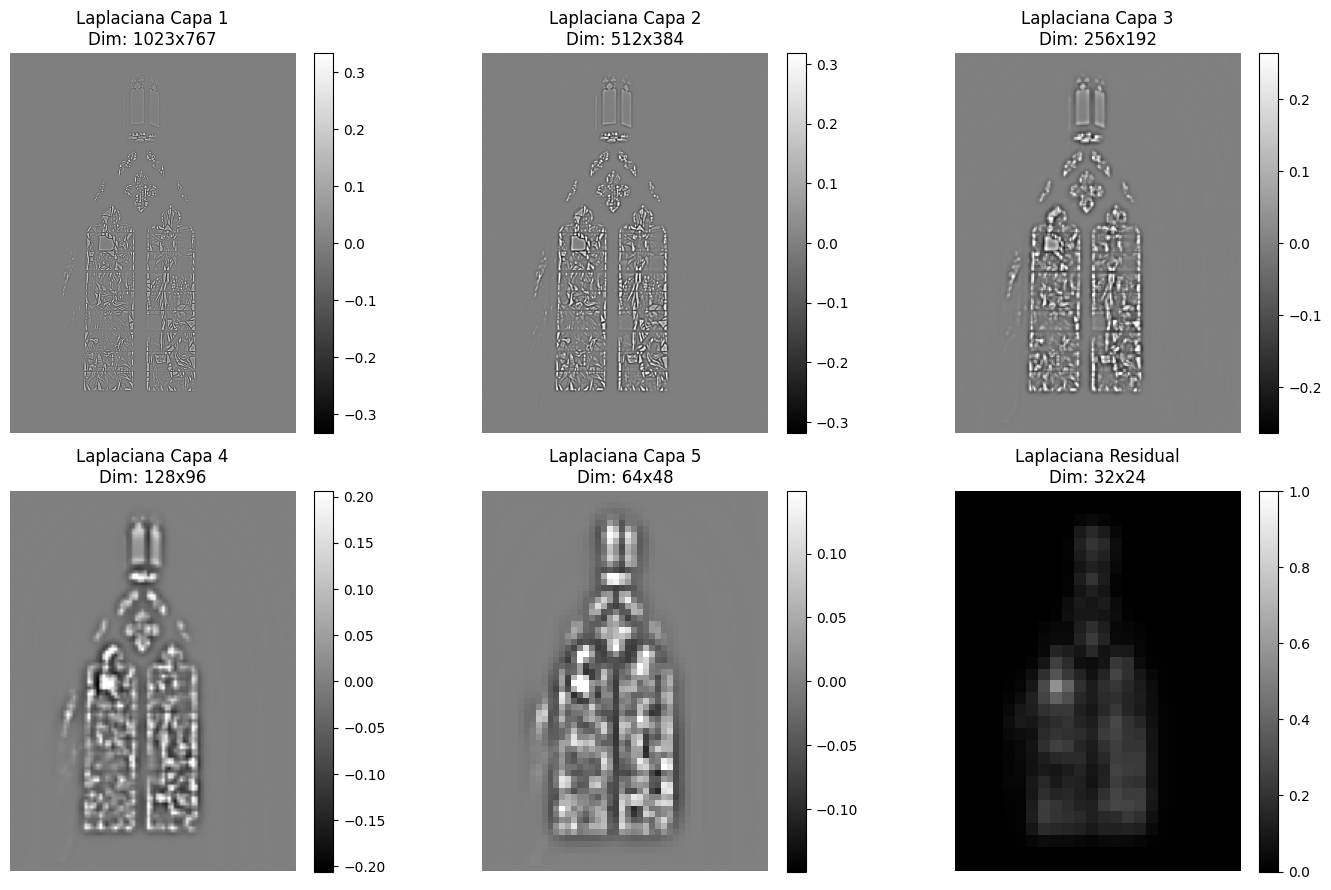

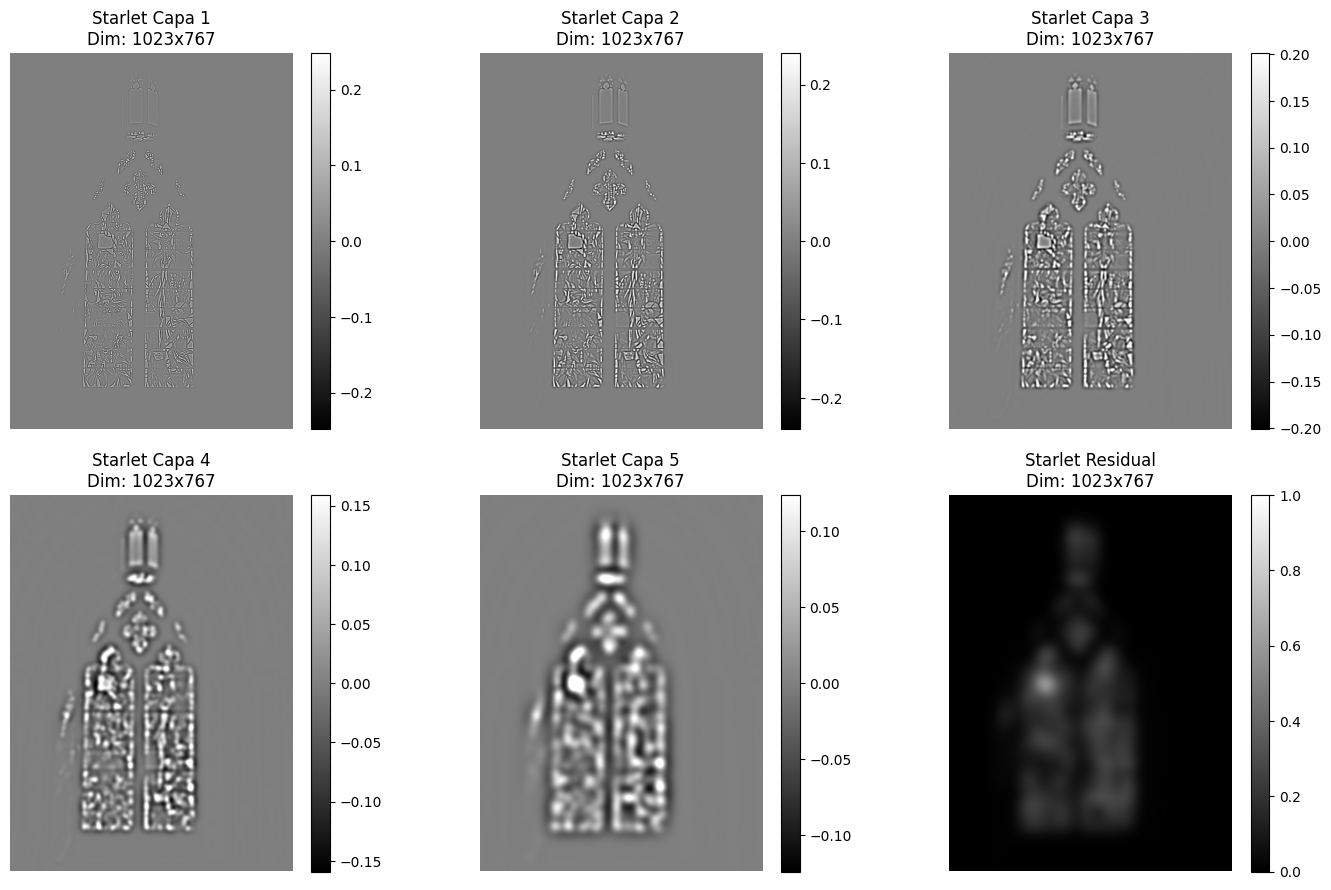

In [38]:
# 4. Visualización de capas
p1.plot_capas(lap_detalles, lap_res, title_prefix="Laplaciana")
p1.plot_capas(star_detalles, star_res, title_prefix="Starlet")
plt.show()

### 2. Experimento: Umbral Duro Relativo (Hard Thresholding)
Aplicamos $T_j = \alpha \cdot \max(|d_j|)$ para $\alpha = 0.05$ y $\alpha = 0.20$.

=== RESULTADOS PARA ALPHA = 0.05 ===
Laplaciana - Coef. Conservados %: [np.float64(11.15), np.float64(14.31), np.float64(17.21), np.float64(20.18), np.float64(22.98)] | RMSE: 0.0090
Starlet    - Coef. Conservados %: [np.float64(9.58), np.float64(13.29), np.float64(15.85), np.float64(19.33), np.float64(22.25)] | RMSE: 0.0089



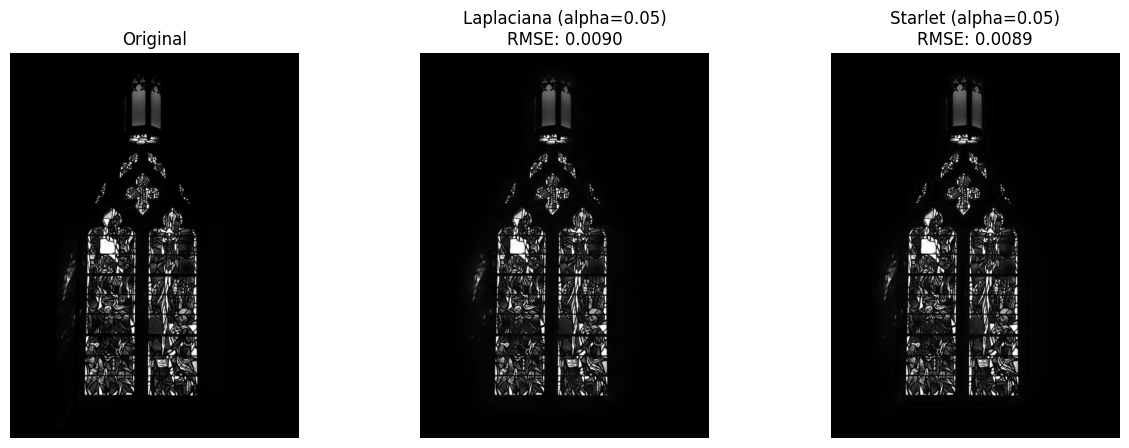

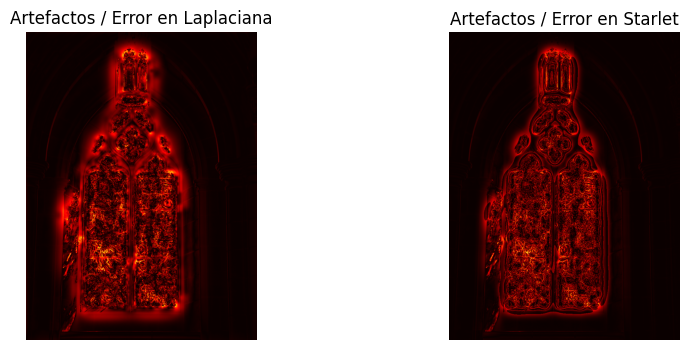

=== RESULTADOS PARA ALPHA = 0.2 ===
Laplaciana - Coef. Conservados %: [np.float64(3.78), np.float64(4.94), np.float64(4.69), np.float64(3.87), np.float64(2.73)] | RMSE: 0.0495
Starlet    - Coef. Conservados %: [np.float64(2.98), np.float64(4.66), np.float64(4.48), np.float64(3.81), np.float64(3.2)] | RMSE: 0.0470



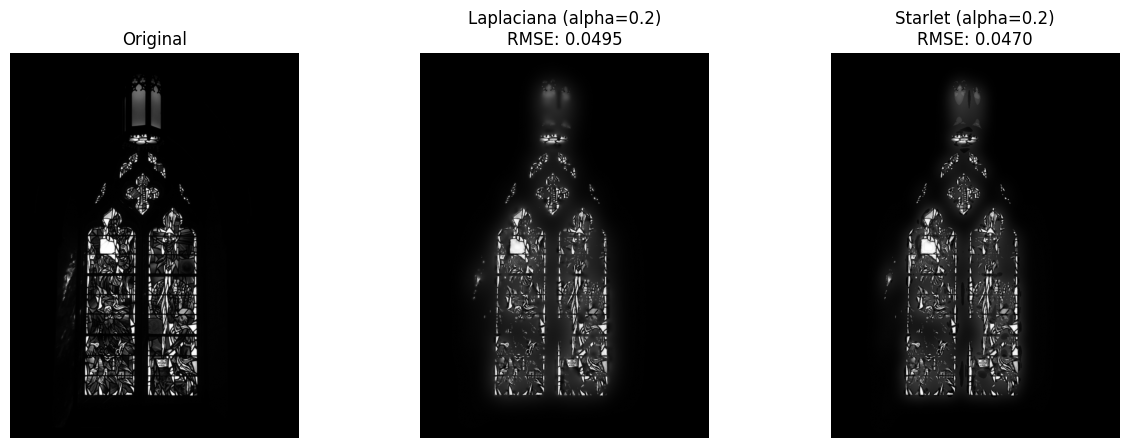

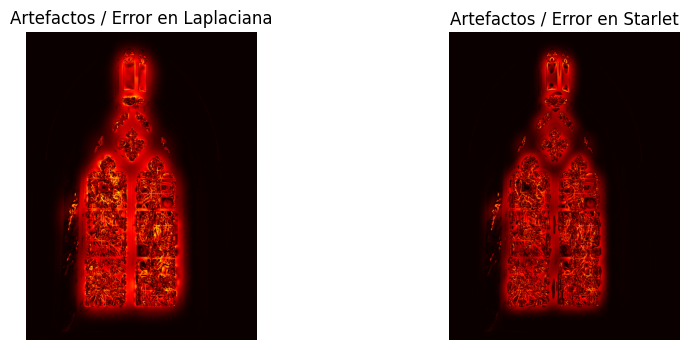

In [43]:
alphas = [0.05, 0.20]

for alpha in alphas:
    lap_th_detalles, lap_pct = p1.umbral_duro(lap_detalles, alpha)
    lap_th_rec = p1.reconstruccion_laplaciana(lap_th_detalles, lap_res)
    lap_th_rmse = p1.calculate_rmse(image, lap_th_rec)
    
    star_th_detalles, star_pct = p1.umbral_duro(star_detalles, alpha)
    star_th_rec = p1.reconstruct_starlet_transform(star_th_detalles, star_res)
    star_th_rmse = p1.calculate_rmse(image, star_th_rec)
    
    print(f'=== RESULTADOS PARA ALPHA = {alpha} ===')
    print(f'Laplaciana - Coef. Conservados %: {[round(p, 2) for p in lap_pct]} | RMSE: {lap_th_rmse:.4f}')
    print(f'Starlet    - Coef. Conservados %: {[round(p, 2) for p in star_pct]} | RMSE: {star_th_rmse:.4f}\n')
    
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(image, cmap='gray')
    axs[0].set_title('Original')
    axs[0].axis('off')
    
    axs[1].imshow(lap_th_rec, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title(f'Laplaciana (alpha={alpha})\nRMSE: {lap_th_rmse:.4f}')
    axs[1].axis('off')
    
    axs[2].imshow(star_th_rec, cmap='gray', vmin=0, vmax=1)
    axs[2].set_title(f'Starlet (alpha={alpha})\nRMSE: {star_th_rmse:.4f}')
    axs[2].axis('off')
    plt.show()

    # diferencia entre la imagen original y la reconstruida
    diferencia_lap = np.abs(image - lap_th_rec)
    diferencia_star = np.abs(image - star_th_rec)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(diferencia_lap, cmap='hot') # 'hot' o 'inferno' resalta los bloques
    plt.title('Artefactos / Error en Laplaciana')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(diferencia_star, cmap='hot')
    plt.title('Artefactos / Error en Starlet')
    plt.axis('off')
    plt.show()

**Análisis de Umbral Duro ($\alpha = 0.05$ vs $\alpha = 0.20$)**

- **Pérdida de detalle:** Al aumentar $\alpha$ a $0.20$, la conservación de coeficientes cae por debajo del $5\%$, eliminando las texturas finas y bordes de menor contraste, lo que eleva el RMSE.
- **Artefactos:** La Pirámide Laplaciana genera artefactos de bloques y distorsión escalonada (ringing) alrededor de las estructuras debido al submuestreo e interpolación. La Transformada Starlet produce un suavizado continuo sin artefactos de grilla.
- **Diferencias:** Starlet logra un RMSE menor y preserva mejor los contornos gracias a su invariancia a la traslación, mientras que la Laplaciana sufre mayor degradación visual por el efecto de la decimación.

### 5. Experimento: Modificación de Ganancias por Escala
Probamos dos configuraciones de factores multiplicativos:
1. **Enfatizar estructuras finas**: ganancias mayores en capas $1$ y $2$.
2. **Enfatizar estructuras gruesas**: ganancias mayores en capas $4$ y $5$.

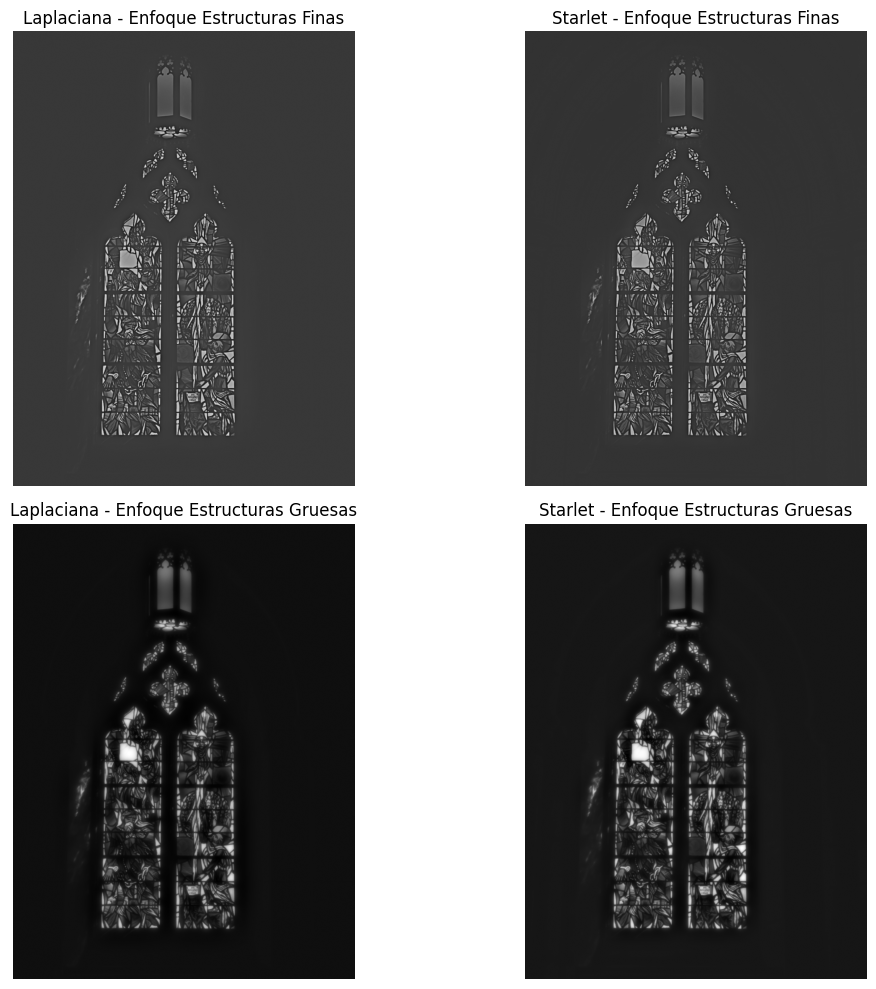

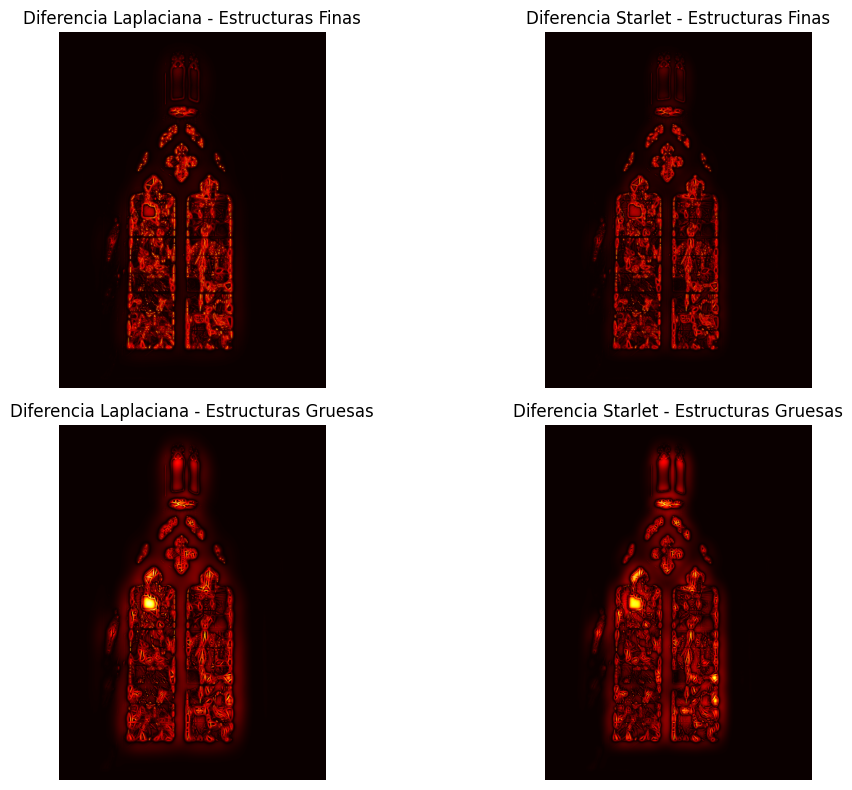

In [46]:
ganancias_finas = [2.0, 1.5, 1.0, 0.8, 0.5]
ganancias_gruesas = [0.5, 0.8, 1.0, 1.5, 2.0]

# Enfoque en finas
lap_fine = p1.reconstruccion_laplaciana(p1.aplicar_factor_mult(lap_detalles, ganancias_finas), lap_res)
star_fine = p1.reconstruct_starlet_transform(p1.aplicar_factor_mult(star_detalles, ganancias_finas), star_res)

# Enfoque en gruesas
lap_coarse = p1.reconstruccion_laplaciana(p1.aplicar_factor_mult(lap_detalles, ganancias_gruesas), lap_res)
star_coarse = p1.reconstruct_starlet_transform(p1.aplicar_factor_mult(star_detalles, ganancias_gruesas), star_res)

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
axs[0, 0].imshow(lap_fine, cmap='gray')
axs[0, 0].set_title('Laplaciana - Enfoque Estructuras Finas')
axs[0, 0].axis('off')

axs[0, 1].imshow(star_fine, cmap='gray')
axs[0, 1].set_title('Starlet - Enfoque Estructuras Finas')
axs[0, 1].axis('off')

axs[1, 0].imshow(lap_coarse, cmap='gray')
axs[1, 0].set_title('Laplaciana - Enfoque Estructuras Gruesas')
axs[1, 0].axis('off')

axs[1, 1].imshow(star_coarse, cmap='gray')
axs[1, 1].set_title('Starlet - Enfoque Estructuras Gruesas')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

# visualizar diferencias entre las imágenes originales y las reconstruidas
diferencia_lap_fine = np.abs(image - lap_fine)
diferencia_star_fine = np.abs(image - star_fine)
diferencia_lap_coarse = np.abs(image - lap_coarse)
diferencia_star_coarse = np.abs(image - star_coarse)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(diferencia_lap_fine, cmap='hot')
plt.title('Diferencia Laplaciana - Estructuras Finas')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(diferencia_star_fine, cmap='hot')
plt.title('Diferencia Starlet - Estructuras Finas')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.imshow(diferencia_lap_coarse, cmap='hot')
plt.title('Diferencia Laplaciana - Estructuras Gruesas')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(diferencia_star_coarse, cmap='hot')
plt.title('Diferencia Starlet - Estructuras Gruesas')
plt.axis('off')
plt.tight_layout()
plt.show()

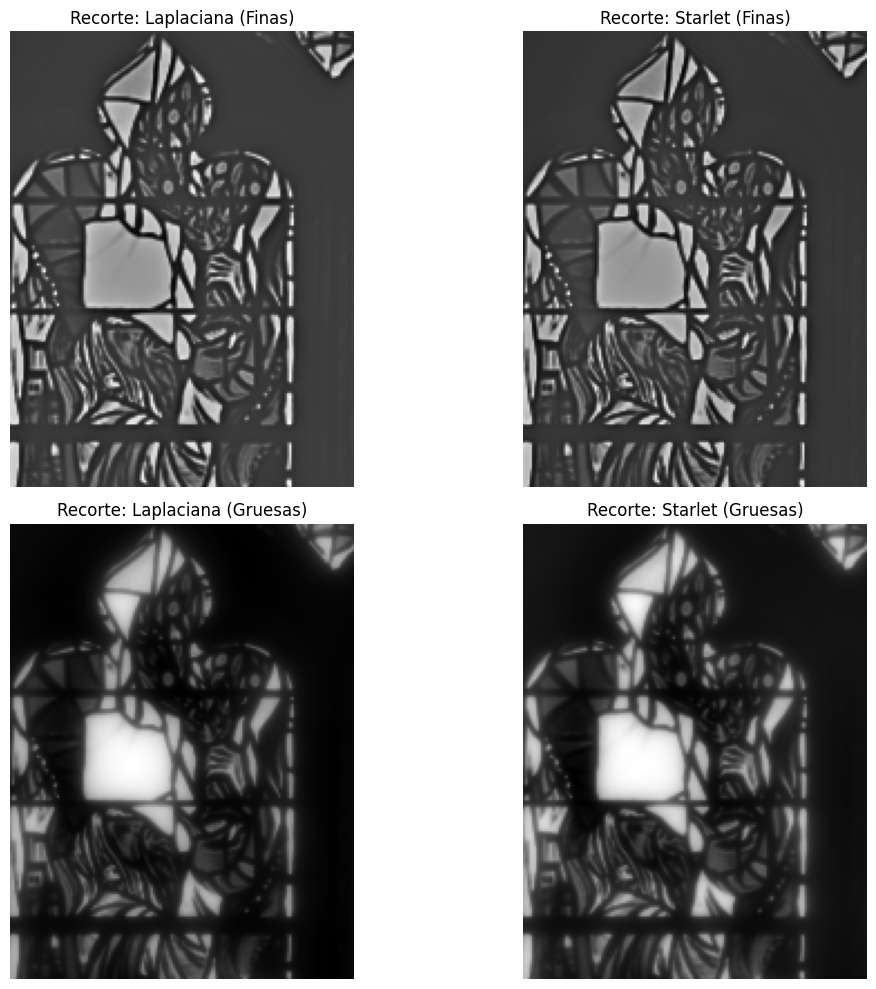

In [50]:
# Region recorte
H, W = image.shape
y1, y2 = int(H * 0.40), int(H * 0.60)
x1, x2 = int(W * 0.40)-100, int(W * 0.60)-100

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Recortes en Estructuras Finas
axs[0, 0].imshow(lap_fine[y1:y2, x1:x2], cmap='gray')
axs[0, 0].set_title('Recorte: Laplaciana (Finas)')
axs[0, 0].axis('off')

axs[0, 1].imshow(star_fine[y1:y2, x1:x2], cmap='gray')
axs[0, 1].set_title('Recorte: Starlet (Finas)')
axs[0, 1].axis('off')

# Recortes en Estructuras Gruesas
axs[1, 0].imshow(lap_coarse[y1:y2, x1:x2], cmap='gray')
axs[1, 0].set_title('Recorte: Laplaciana (Gruesas)')
axs[1, 0].axis('off')

axs[1, 1].imshow(star_coarse[y1:y2, x1:x2], cmap='gray')
axs[1, 1].set_title('Recorte: Starlet (Gruesas)')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

**Comparación de Ganancias por Escala**

- **Enfoque en Estructuras Finas:** Aumentar la ganancia de los primeros niveles ($d_1, d_2$) produce un efecto de agudizado, resaltando bordes nítidos y texturas de alta frecuencia a costa de atenuar la iluminación de fondo.
- **Enfoque en Estructuras Gruesas:** Aumentar la ganancia de las capas superiores ($d_4, d_5$) suaviza el detalle fino y resalta el contraste regional.